# 05 Hybrid Risk Engine

This notebook adds a transparent Academic-Financial Stress Index (AFSI), combines it with the calibrated machine-learning probability, and evaluates a cautious counterfactual recommender. It rebuilds the final model from notebook 04 without changing earlier notebooks or results.

### Reproducibility and model definition

All randomness uses seed 42. The split is the same stratified 80/20 split used by the project. The final model is Logistic Regression with balanced class weights and isotonic calibration. The test set is used only once for the final evaluation.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, brier_score_loss, recall_score, roc_auc_score,
)
from sklearn.model_selection import cross_val_predict, StratifiedKFold

from data_utils import load_data, prepare_model_data, split_data
from model_utils import make_pipeline
from custom_algorithms import AFSI_WEIGHTS, afsi, hybrid_score, recommend
from plot_utils import save_figure, set_style

SEED = 42
set_style()
data = load_data()
model_data = prepare_model_data(data)
X_train, X_test, y_train, y_test = split_data(model_data, random_state=SEED)

base = make_pipeline("logistic_regression", X_train.columns, "class_weight", SEED)
final_model = CalibratedClassifierCV(estimator=base, method="isotonic", cv=5)
final_model.fit(X_train, y_train)
ml_train = cross_val_predict(
    CalibratedClassifierCV(
        estimator=make_pipeline("logistic_regression", X_train.columns, "class_weight", SEED),
        method="isotonic", cv=5,
    ),
    X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    method="predict_proba",
)[:, 1]
ml_test = final_model.predict_proba(X_test)[:, 1]
afsi_train = afsi(X_train)
afsi_test = afsi(X_test)
print(f"Train/test rows: {len(X_train)}/{len(X_test)}")

Train/test rows: 3539/885


### AFSI formula

AFSI is deliberately transparent: low approval, financial risk, and a grade decline increase the score. The weights are kept in one dictionary in `src/custom_algorithms.py`, so a student can inspect or change them.

In [2]:
print("AFSI weights:", AFSI_WEIGHTS)
print(pd.Series(afsi_test).describe().round(2))

AFSI weights: {'approval_1st': 0.3, 'approval_2nd': 0.4, 'financial_risk': 0.2, 'grade_decline': 0.1}
count    885.00
mean      29.99
std       28.27
min        0.00
25%       10.00
50%       18.33
75%       50.00
max       95.71
dtype: float64


### Selecting alpha without test-set tuning

For each alpha from 0 to 1, use only out-of-fold calibrated probabilities from the training set. The selected value maximises training PR-AUC; the test set is not consulted.

In [3]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
alpha_scores = {
    alpha: average_precision_score(y_train, hybrid_score(ml_train, afsi_train, alpha))
    for alpha in alphas
}
alpha = max(alpha_scores, key=alpha_scores.get)
print("Selected alpha:", alpha, "training PR-AUC:", round(alpha_scores[alpha], 4))

Selected alpha: 0.9 training PR-AUC: 0.8711


### One final test-set comparison

The four scorers are ML only, AFSI only, the selected hybrid, and a Random Forest baseline. The Random Forest is fitted on training data only. Metrics use continuous scores except recall, which uses the required 0.5 threshold.

,scorer,roc_auc,pr_auc,brier_score,recall_at_0.5
0,ML only,0.9346,0.9002,0.0842,0.7606
1,AFSI only,0.9124,0.8451,0.1068,0.6796
2,Hybrid,0.9358,0.9043,0.0839,0.7535
3,Random Forest,0.9305,0.9006,0.0891,0.7324


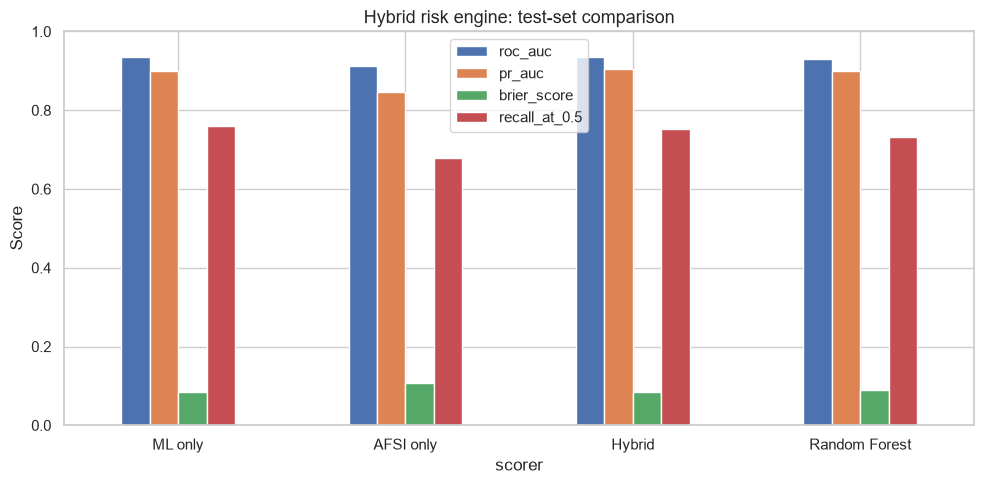

In [4]:
rf = make_pipeline("random_forest", X_train.columns, "none", SEED)
rf.fit(X_train, y_train)
rf_test = rf.predict_proba(X_test)[:, 1]
scores = {
    "ML only": ml_test,
    "AFSI only": afsi_test / 100,
    "Hybrid": hybrid_score(ml_test, afsi_test, alpha),
    "Random Forest": rf_test,
}
rows = []
for name, probability in scores.items():
    rows.append({
        "scorer": name,
        "roc_auc": roc_auc_score(y_test, probability),
        "pr_auc": average_precision_score(y_test, probability),
        "brier_score": brier_score_loss(y_test, probability),
        "recall_at_0.5": recall_score(y_test, probability >= 0.5),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv("../results/tables/hybrid_comparison.csv", index=False)
display(comparison.round(4))
comparison.set_index("scorer").plot(kind="bar", figsize=(10, 5), rot=0)
plt.title("Hybrid risk engine: test-set comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
save_figure("fig15_hybrid_comparison.png")
plt.show()

### AFSI-weight sensitivity

Each AFSI weight is changed by +0.1 and -0.1, then all weights are re-normalised. This is a small robustness check, not another opportunity to tune the test set. The honest result is reported below.

In [5]:
sensitivity_rows = [{"change": "Baseline", "hybrid_roc_auc": roc_auc_score(y_test, scores["Hybrid"])}]
for key in AFSI_WEIGHTS:
    for delta in (-0.1, 0.1):
        changed = dict(AFSI_WEIGHTS)
        changed[key] = max(0, changed[key] + delta)
        total = sum(changed.values())
        changed = {name: value / total for name, value in changed.items()}
        changed_test = afsi(X_test, changed)
        sensitivity_rows.append({
            "change": f"{key} {delta:+.1f}",
            "hybrid_roc_auc": roc_auc_score(y_test, hybrid_score(ml_test, changed_test, alpha)),
        })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv("../results/tables/afsi_sensitivity.csv", index=False)
display(sensitivity.round(4))
best_hybrid = comparison.loc[comparison.scorer == "Hybrid", "roc_auc"].iloc[0]
best_ml = comparison.loc[comparison.scorer == "ML only", "roc_auc"].iloc[0]
print("Conclusion:", "Hybrid beats ML only." if best_hybrid > best_ml else "Hybrid does not beat ML only; the calibrated ML probability already captures the available signal, while AFSI is intentionally simple and transparent.")


,change,hybrid_roc_auc
0,Baseline,0.9358
1,approval_1st -0.1,0.9355
2,approval_1st +0.1,0.9360
3,approval_2nd -0.1,0.9356
4,approval_2nd +0.1,0.9357
5,financial_risk -0.1,0.9359
6,financial_risk +0.1,0.9355
7,grade_decline -0.1,0.9354
8,grade_decline +0.1,0.9355


Conclusion: Hybrid beats ML only.


### Visualising sensitivity results

This chart makes the small changes in hybrid ROC-AUC easy to compare with the ML-only reference.

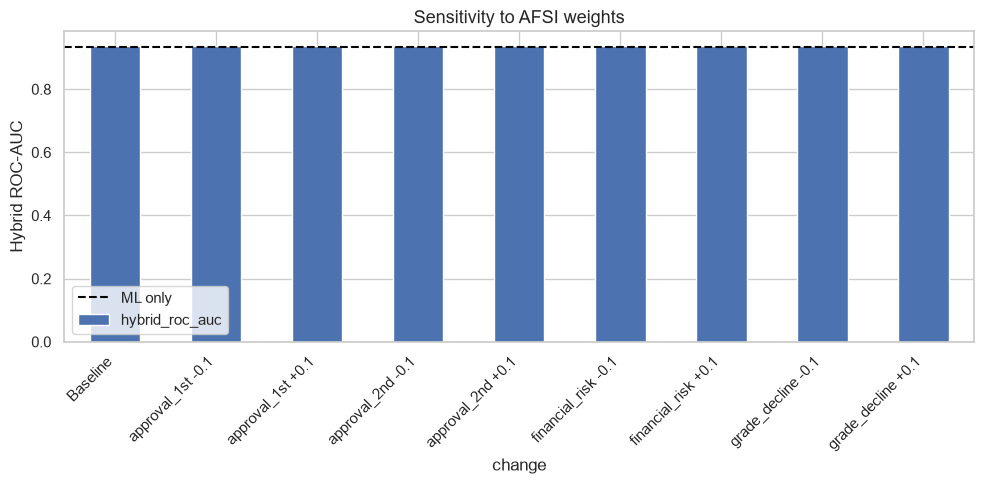

In [6]:
sensitivity.plot(x="change", y="hybrid_roc_auc", kind="bar", legend=False, figsize=(10, 5), color="#4c72b0")
plt.axhline(best_ml, color="black", linestyle="--", label="ML only")
plt.ylabel("Hybrid ROC-AUC")
plt.title("Sensitivity to AFSI weights")
plt.xticks(rotation=45, ha="right")
plt.legend()
save_figure("fig16_afsi_sensitivity.png")
plt.show()

### Risk tiers and dropout rates

The same Low (<0.30), Medium (0.30 to 0.60), and High (>0.60) cut-offs are applied to ML-only and hybrid scores. This makes the tier comparison directly interpretable.

,scorer,tier,students,dropout_rate
0,ML only,Low,578,0.0744
1,ML only,Medium,86,0.4884
2,ML only,High,221,0.9005
3,Hybrid,Low,578,0.0727
4,Hybrid,Medium,88,0.5000
5,Hybrid,High,219,0.9041


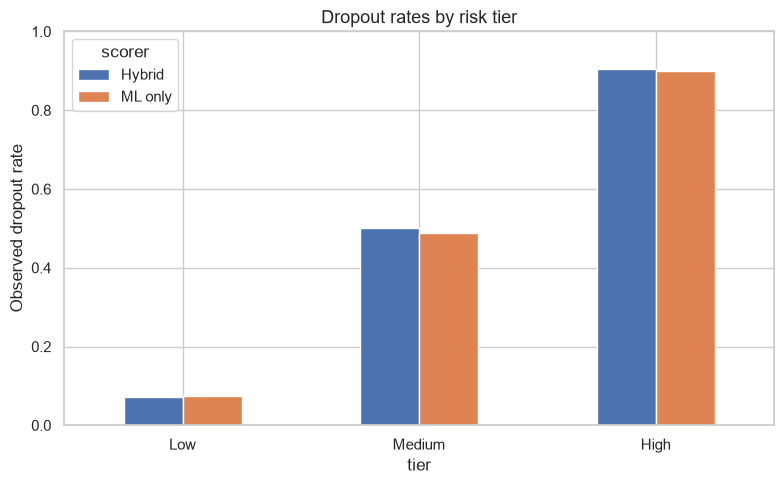

In [7]:
def make_tiers(probability):
    return pd.cut(probability, [-np.inf, 0.30, 0.60, np.inf], labels=["Low", "Medium", "High"], right=True)

ml_tiers = make_tiers(ml_test)
hybrid_test = scores["Hybrid"]
hybrid_tiers = make_tiers(hybrid_test)
tier_rows = []
for scorer, tiers in [("ML only", ml_tiers), ("Hybrid", hybrid_tiers)]:
    for tier in ["Low", "Medium", "High"]:
        mask = tiers == tier
        tier_rows.append({"scorer": scorer, "tier": tier, "students": int(mask.sum()), "dropout_rate": y_test[mask].mean()})
tier_table = pd.DataFrame(tier_rows)
tier_table.to_csv("../results/tables/hybrid_tier_summary.csv", index=False)
display(tier_table.round(4))
tier_plot = tier_table.pivot(index="tier", columns="scorer", values="dropout_rate")
tier_plot.loc[["Low", "Medium", "High"]].plot(kind="bar", figsize=(8, 5), rot=0)
plt.ylabel("Observed dropout rate")
plt.title("Dropout rates by risk tier")
plt.ylim(0, 1)
save_figure("fig18_hybrid_tier_dropout.png")
plt.show()

### Counterfactual recommendation

The recommender changes only tuition status, debtor status, approved units, and second-semester grade. It greedily tests one permitted change at a time and stops at the target probability or after three steps. These are model-based associations, not proof that making a change would cause lower dropout; recommendations are decision support only.

In [8]:
high_indices = np.where(np.asarray(ml_tiers.astype(str)) == "High")[0]
recommendation_rows = []
all_changes = []
for index in high_indices:
    row = data.iloc[X_test.index[index]]
    before = ml_test[index]
    changes = recommend(row, final_model, max_steps=3, target=0.30)
    after = before
    if changes:
        after = float(changes[-1].split(" to ")[-1].rstrip("%")) / 100
    all_changes.extend([change.split(":")[0] for change in changes])
    recommendation_rows.append({
        "index": int(X_test.index[index]), "before_probability": before,
        "steps": " | ".join(changes), "after_probability": after,
        "reached_below_high": after < 0.60, "reached_below_medium": after < 0.30,
        "probability_reduction": before - after,
    })
recommendations = pd.DataFrame(recommendation_rows)
if recommendations.empty:
    summary = pd.DataFrame([{"high_students": 0, "below_high_pct": np.nan, "below_medium_pct": np.nan, "average_probability_reduction": np.nan, "most_frequent_change": "None"}])
else:
    counts = pd.Series(all_changes).value_counts()
    summary = pd.DataFrame([{
        "high_students": len(recommendations),
        "below_high_pct": recommendations.reached_below_high.mean(),
        "below_medium_pct": recommendations.reached_below_medium.mean(),
        "average_probability_reduction": recommendations.probability_reduction.mean(),
        "most_frequent_change": counts.index[0] if len(counts) else "None",
    }])
summary.to_csv("../results/tables/recommender_summary.csv", index=False)
examples = recommendations.head(3).copy()
examples.to_csv("../results/tables/recommender_examples.csv", index=False)
display(summary.round(4))
display(examples)

,high_students,below_high_pct,below_medium_pct,average_probability_reduction,most_frequent_change
0,221,0.3258,0.1357,0.2196,Approve one more second-semester unit


,index,before_probability,steps,after_probability,reached_below_high,reached_below_medium,probability_reduction
0,2266,0.983676,Approve one more second-semester unit: 98% to ...,0.86,False,False,0.123676
1,3861,0.980957,Approve one more first-semester unit: 98% to 9...,0.93,False,False,0.050957
2,971,0.918600,Approve one more second-semester unit: 92% to ...,0.78,False,False,0.138600


### Recommendation frequency

Only changes selected by at least one High-tier test student are plotted. An empty chart is avoided when no student has a valid greedy improvement.

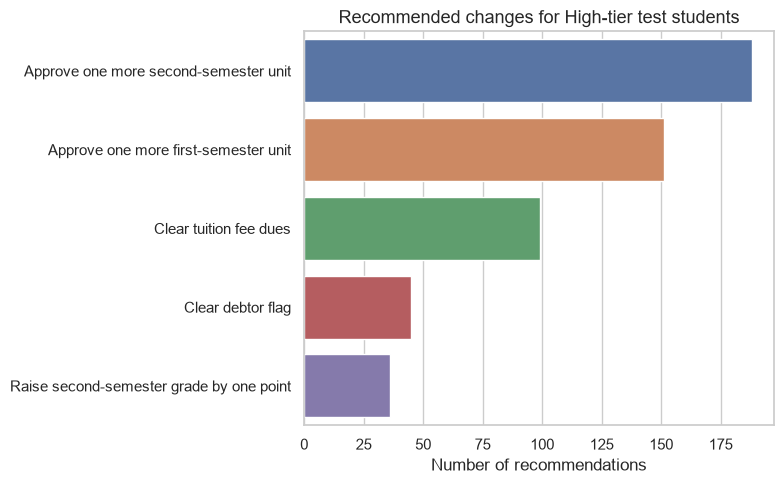

In [9]:
frequency = pd.Series(all_changes).value_counts().rename_axis("change").reset_index(name="count")
if frequency.empty:
    frequency = pd.DataFrame({"change": ["No improving recommendation"], "count": [0]})
sns.barplot(data=frequency, x="count", y="change", hue="change", legend=False, palette="deep")
plt.title("Recommended changes for High-tier test students")
plt.xlabel("Number of recommendations")
plt.ylabel("")
save_figure("fig17_recommendation_frequency.png")
plt.show()

### Interpretation and limitations

The hybrid is useful only if it improves the chosen metric without hiding calibration or fairness concerns. AFSI is intentionally understandable, but it compresses complex student circumstances into four inputs. The recommender is not causal, does not alter protected or non-actionable attributes, and must not be used for punitive decisions.